# **CHL5207Y Fall Assignment - Report Code**
#### Submission by Alex Chen

### Package Imports

In [ ]:
# Note: assumes Python version 3.14.3+
# !pip install statsmodels

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import math

from IPython.display import display
from matplotlib.axes import Axes
from matplotlib.figure import Figure

# from sklearn.linear_model import LinearRegression
# from sklearn.model_selection import train_test_split
from statsmodels.formula.api import ols
from statsmodels.nonparametric.smoothers_lowess import lowess

## **Part 1 - Relationships among the Ratings**

### Import Dataset + EDA

Note: ensure that "Rateprof.csv" is located at the root of the directory where this notebook is located/being run from.

In [ ]:
rateProf = pd.read_csv("./Rateprof.csv")
rateVars = ["quality", "helpfulness", "clarity", "easiness", "raterInterest"]

In [4]:
display(rateProf.head())
display(rateProf.tail())
display(rateProf.dtypes)

,Unnamed: 0,gender,numYears,numRaters,numCourses,pepper,discipline,dept,quality,helpfulness,clarity,easiness,raterInterest,sdQuality,sdHelpfulness,sdClarity,sdEasiness,sdRaterInterest
0,1,male,7,11,5,no,Hum,English,4.636364,4.636364,4.636364,4.818182,3.545455,0.551856,0.674200,0.504525,0.404520,1.128152
1,2,male,6,11,5,no,Hum,Religious Studies,4.318182,4.545455,4.090909,4.363636,4.000000,0.902018,0.934199,0.943880,0.504525,1.074436
2,3,male,10,43,2,no,Hum,Art,4.790698,4.720930,4.860465,4.604651,3.432432,0.452934,0.666390,0.412968,0.540702,1.236944
3,4,male,11,24,5,no,Hum,English,4.250000,4.458333,4.041667,2.791667,3.181818,0.932505,0.931533,0.999094,0.588230,1.332251
4,5,male,11,19,7,no,Hum,Spanish,4.684211,4.684211,4.684211,4.473684,4.214286,0.650011,0.820070,0.582393,0.611775,0.974961


,Unnamed: 0,gender,numYears,numRaters,numCourses,pepper,discipline,dept,quality,helpfulness,clarity,easiness,raterInterest,sdQuality,sdHelpfulness,sdClarity,sdEasiness,sdRaterInterest
361,362,female,5,21,3,no,Pre-prof,Social Work,2.619048,2.714286,2.523810,3.619048,3.411765,1.548425,1.553797,1.691717,1.430950,1.003670
362,363,female,4,15,2,no,Pre-prof,Accounting,2.966667,3.066667,2.866667,2.666667,2.533333,1.288225,1.334523,1.355764,1.447494,1.125463
363,364,female,2,10,3,no,Pre-prof,Accounting,3.250000,3.200000,3.300000,3.000000,2.700000,1.207615,1.475730,1.059350,1.563472,0.948683
364,365,female,9,11,5,no,Pre-prof,Nursing,1.909091,1.909091,1.909091,2.272727,2.545455,1.375103,1.578261,1.300350,1.618080,1.634848
365,366,female,2,11,4,no,Pre-prof,Marketing,1.409091,1.363636,1.454545,2.636364,2.272727,0.917011,0.924416,1.035725,1.629278,1.420627


Unnamed: 0           int64
gender                 str
numYears             int64
numRaters            int64
numCourses           int64
pepper                 str
discipline             str
dept                   str
quality            float64
helpfulness        float64
clarity            float64
easiness           float64
raterInterest      float64
sdQuality          float64
sdHelpfulness      float64
sdClarity          float64
sdEasiness         float64
sdRaterInterest    float64
dtype: object

In [5]:
display(rateProf[rateVars].describe())

,quality,helpfulness,clarity,easiness,raterInterest
count,366.000000,366.000000,366.000000,366.000000,366.000000
mean,3.575058,3.630880,3.524552,3.135368,3.309508
std,0.837492,0.842276,0.858901,0.777716,0.552541
min,1.409091,1.363636,1.333333,1.391304,1.098039
25%,2.936012,3.068519,2.871154,2.548214,2.934375
50%,3.612500,3.662281,3.600000,3.148148,3.305361
75%,4.250000,4.350913,4.214286,3.692308,3.692308
max,4.981481,5.000000,5.000000,4.900000,4.909091


### Check for Missing Data

In [6]:
# Check for NaN/null values
missing = rateProf[rateProf.isna().any(axis=1)]
"No NaN values within dataframe." \
  if missing.shape[0] <= 0 \
  else f"{missing.shape[0]} rows with NaN found."


'No NaN values within dataframe.'

### Create histograms and box-whisker plots to show distribution shape of variables:

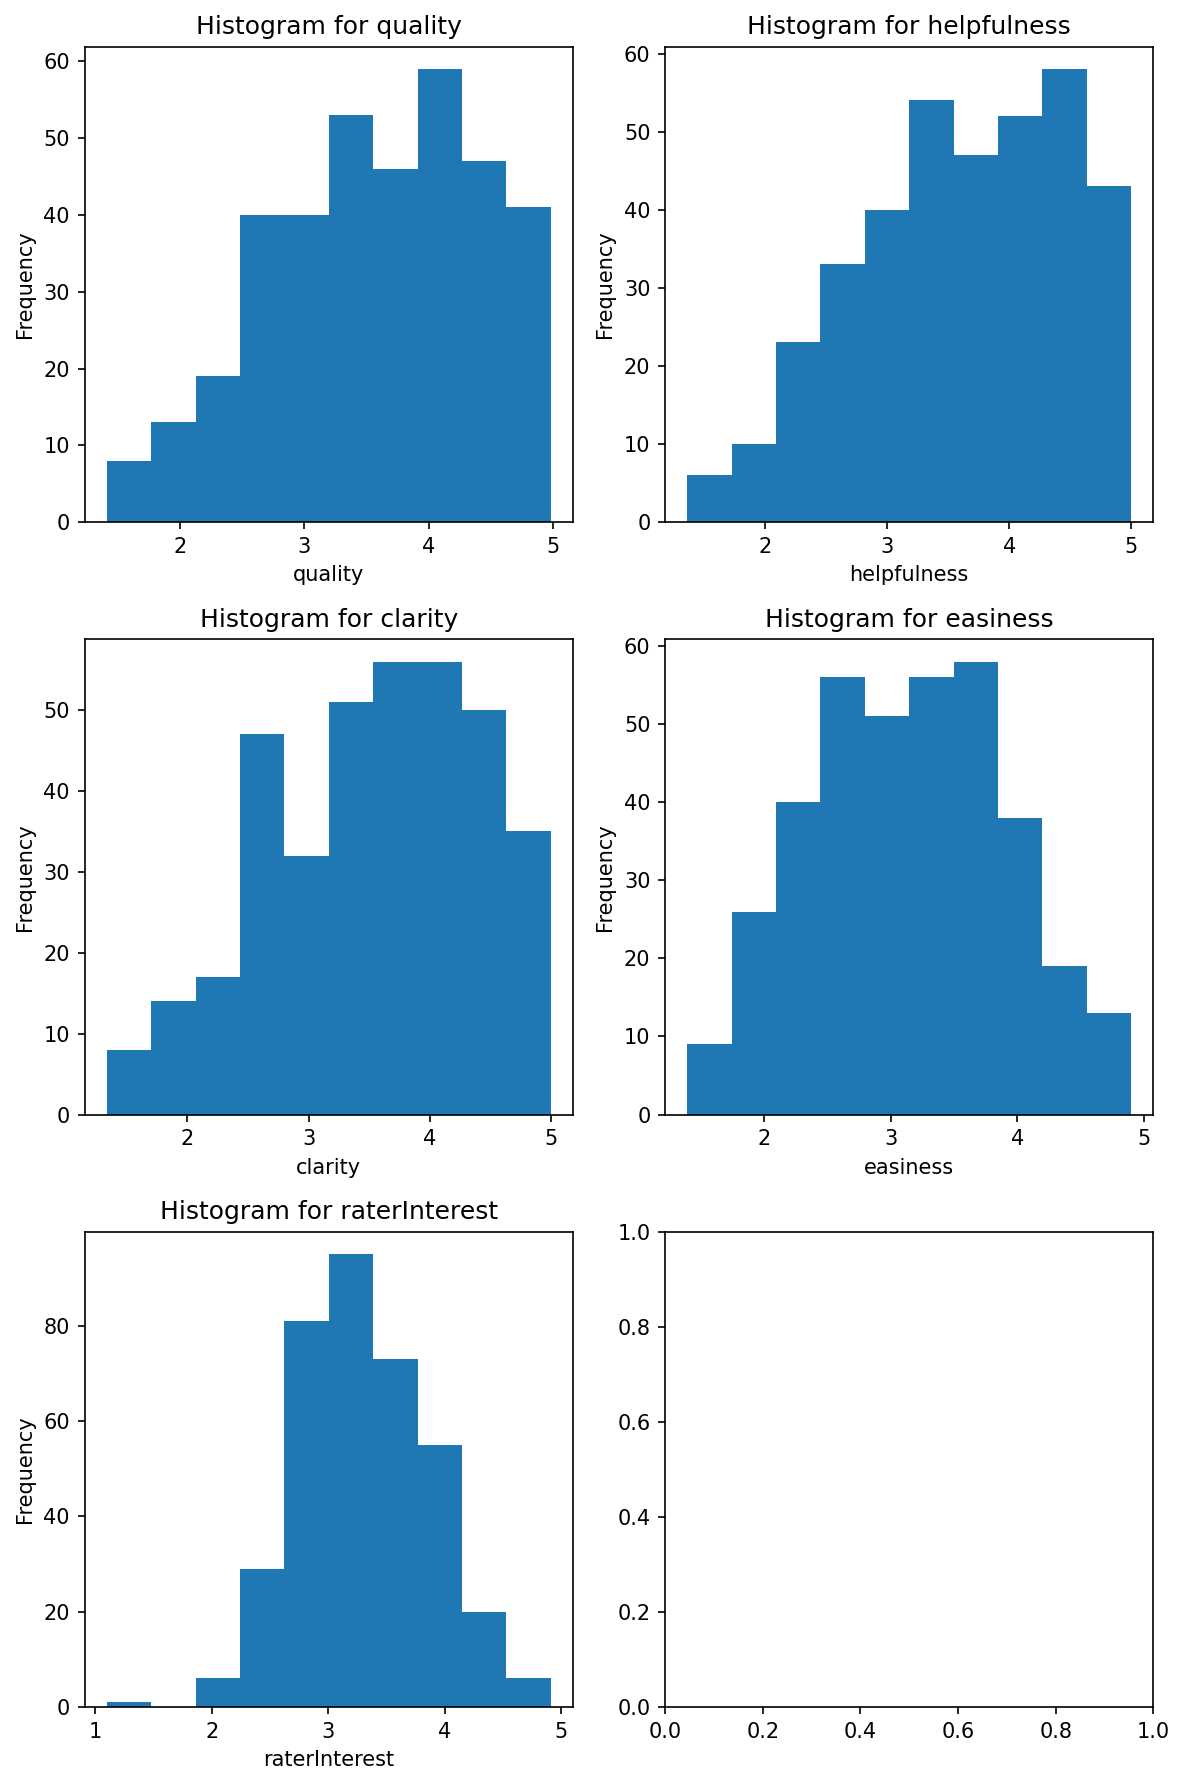

In [7]:
nrows = math.ceil(len(rateVars) / 2)

subplotsHist: tuple[Figure, Axes] = plt.subplots(
  nrows=nrows, 
  ncols=2, 
  figsize=(8, 4 * nrows)
)
_, axesH = subplotsHist

for (varIdx, rateVar) in enumerate(rateVars):
  rowNum = math.floor(varIdx / 2)
  colNum = varIdx % 2
  # print(f"{col} Histogram:")
  axesH[rowNum, colNum].hist(rateProf[rateVar])
  axesH[rowNum, colNum].set_title(f"Histogram for {rateVar}")
  axesH[rowNum, colNum].set_xlabel(rateVar)
  axesH[rowNum, colNum].set_ylabel("Frequency")
  # rateProf[varIdx].hist(figsize=(4, 4))

plt.tight_layout()
plt.show()

All 5 variables appear to roughly follow some sort of unimodal distribution (`quality`, `helpfulness`, and `clarity` appear noticeably negatively skewed). `raterInterest` shows a tiny frequency of points close to 1, isolated from the rest of the distribution; this may point to a rare outlier rather than abnormally-marked missing values.

<Axes: >

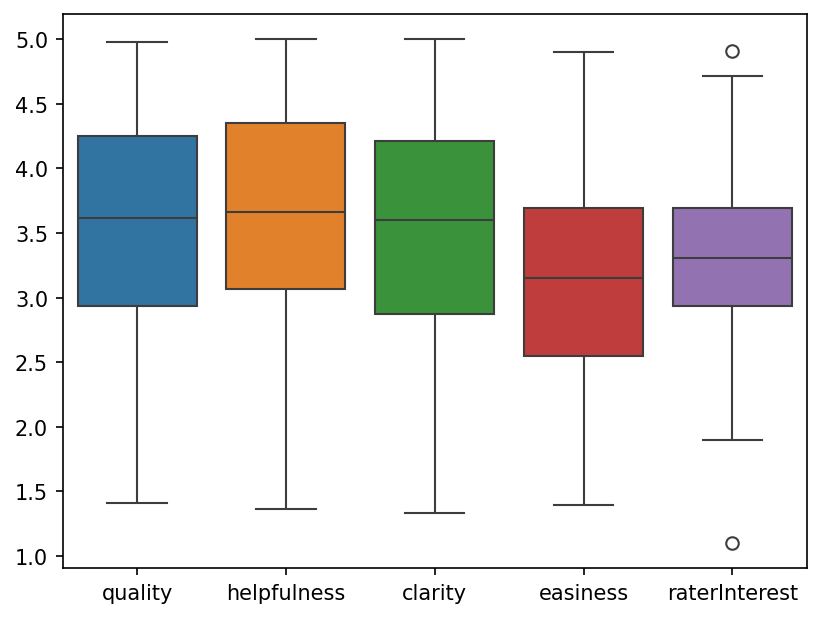

In [8]:
sns.boxplot(data=rateProf[rateVars])

### Observe relationships between variables through scatterplots

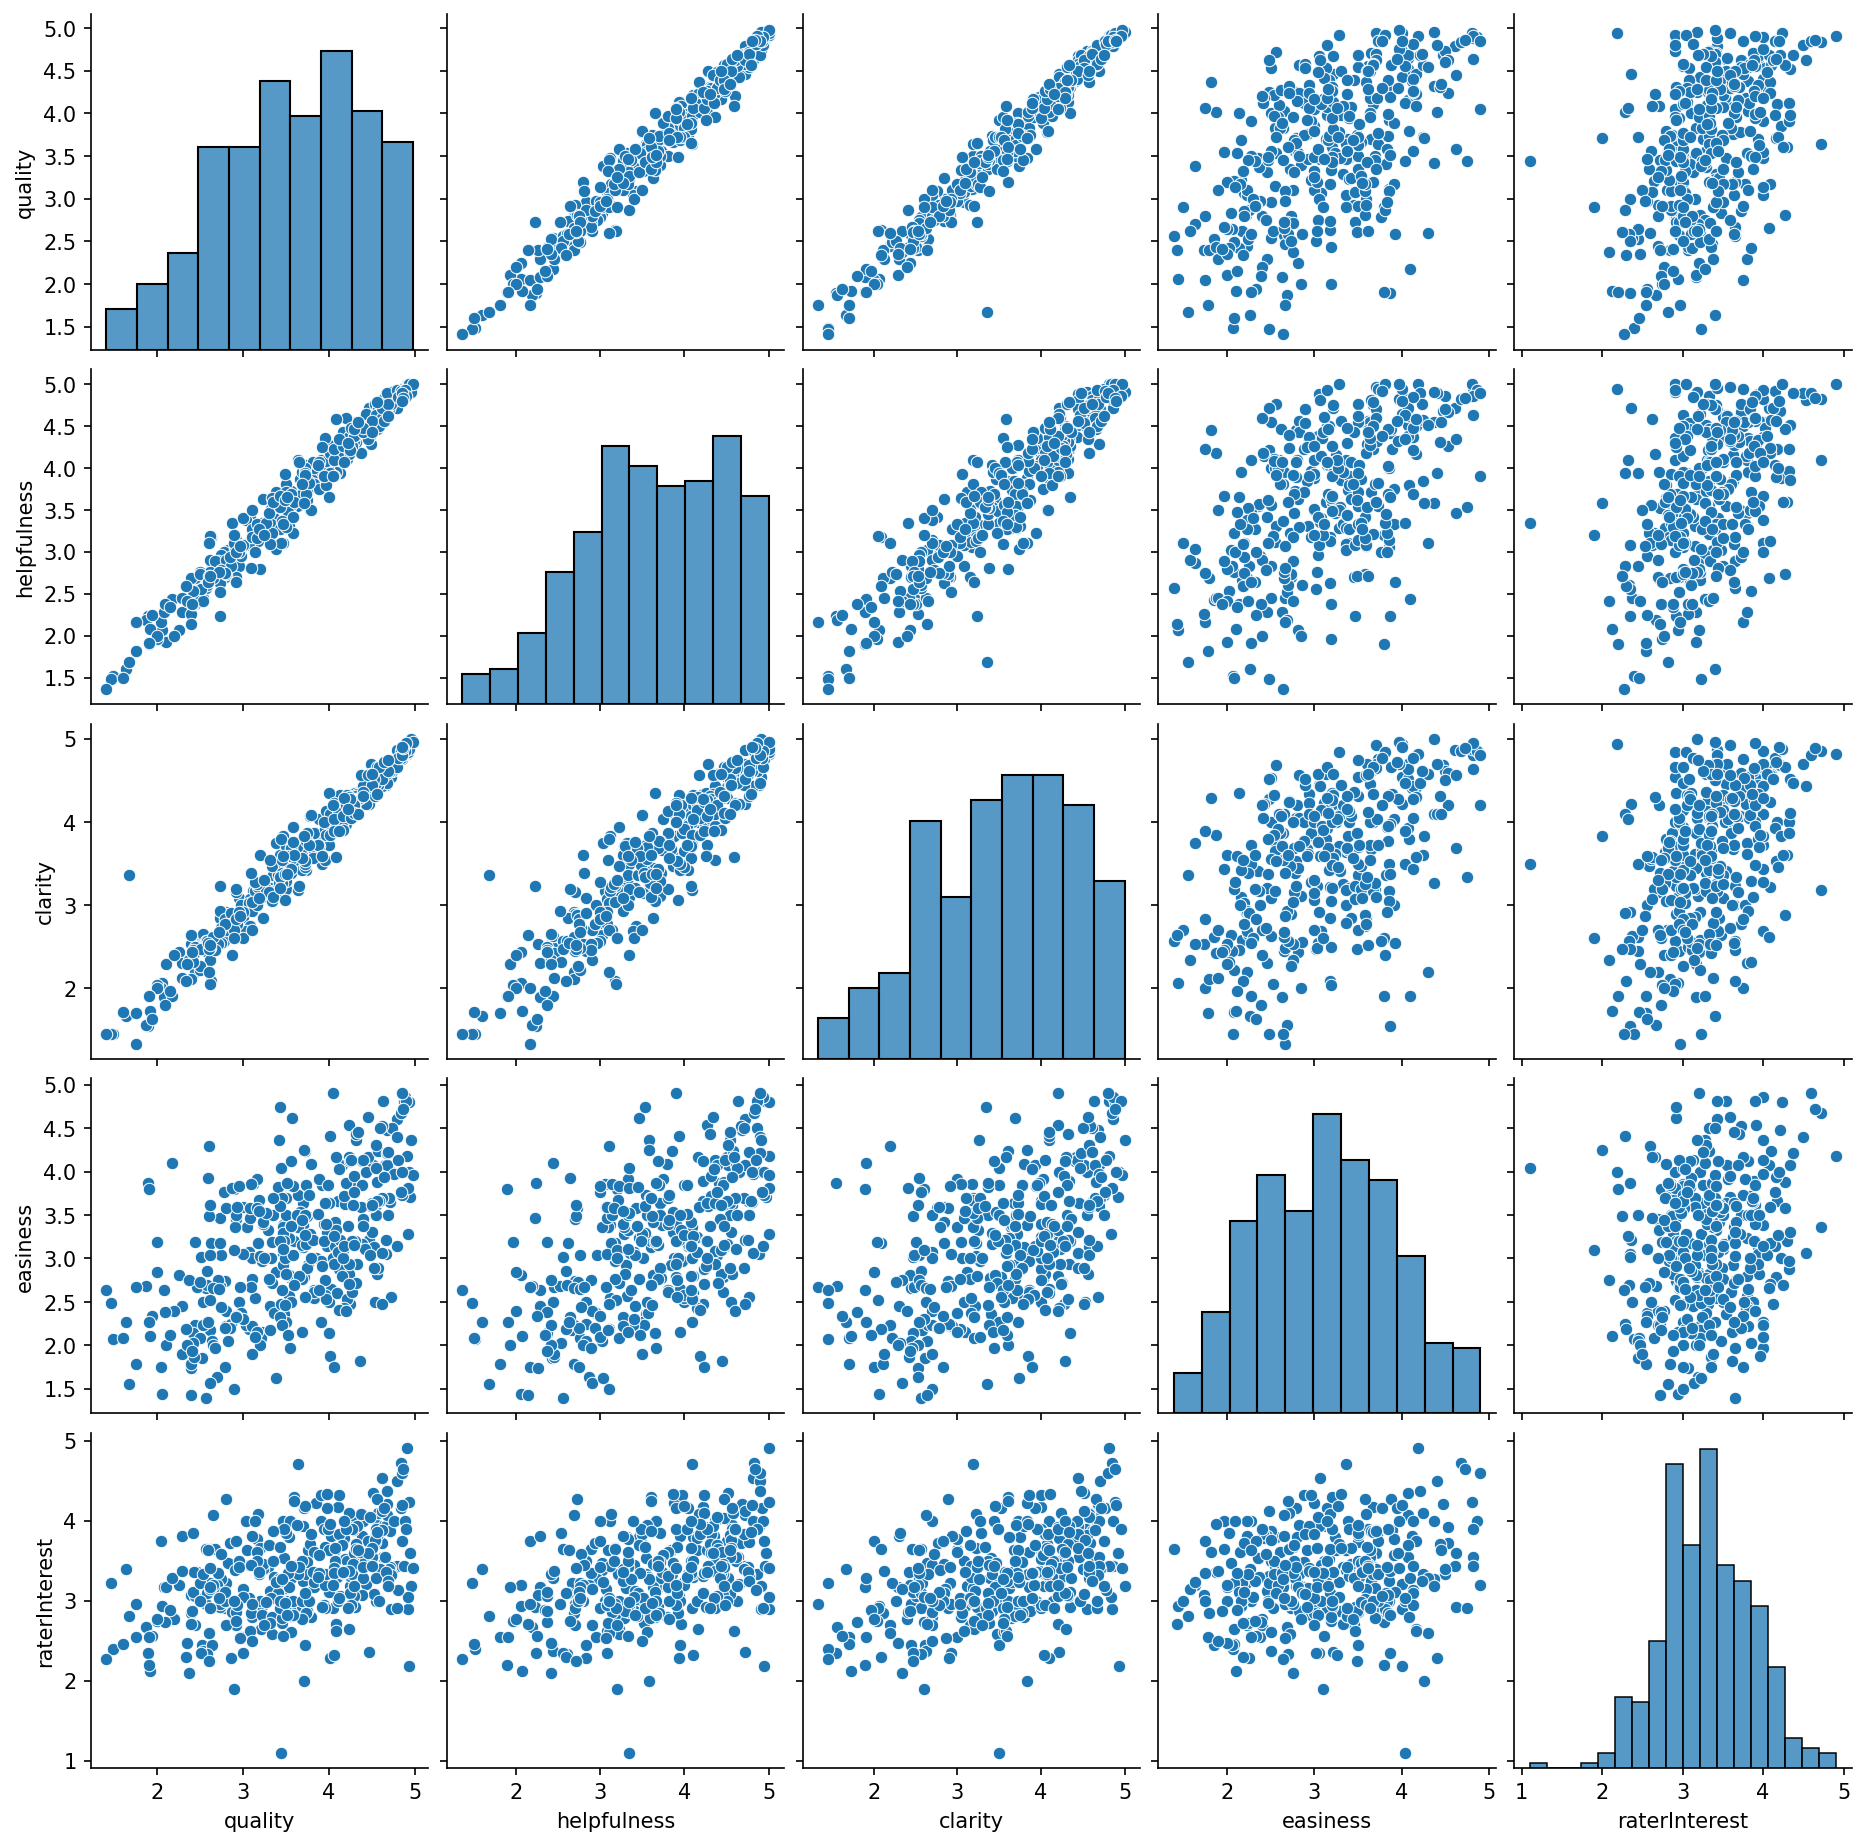

In [9]:
sns.pairplot(rateProf[rateVars])
plt.show()

From scatterplots above, we can clearly see a strong positive linear relationship between quality vs (clarity, helpfulness), and helpfulness vs clarity. With other covariate combinations the trend is much less clear, but can still be considered relatively positive.

### Correlation Calculations

In [10]:
display(rateProf[rateVars].corr(method="pearson"))
display(rateProf[rateVars].corr(method="spearman"))


,quality,helpfulness,clarity,easiness,raterInterest
quality,1.000000,0.981031,0.975961,0.565115,0.470669
helpfulness,0.981031,1.000000,0.920807,0.563518,0.463032
clarity,0.975961,0.920807,1.000000,0.535888,0.461141
easiness,0.565115,0.563518,0.535888,1.000000,0.205224
raterInterest,0.470669,0.463032,0.461141,0.205224,1.000000


,quality,helpfulness,clarity,easiness,raterInterest
quality,1.000000,0.980526,0.978526,0.559384,0.472498
helpfulness,0.980526,1.000000,0.923914,0.555252,0.460995
clarity,0.978526,0.923914,1.000000,0.532272,0.462663
easiness,0.559384,0.555252,0.532272,1.000000,0.191335
raterInterest,0.472498,0.460995,0.462663,0.191335,1.000000


Quality, helpfulness, and clarity are all nearly perfectly correlated with each other, while the majority of other variables have a moderately positive correlation (raterInterest and easiness have a weak positive correlation). If creating a model predicting quality, conditioning on both covariates helpfulness and clarity may cause multicollinearity.

## **Part 2 - Regression Modelling** (`statsmodels`)

### Investigate and preprocess categorical variables (gender, discipline, pepper, possibly numYears?)

In [11]:
catVars = ["gender", "discipline", "pepper"]
display(rateProf[catVars].describe())

for catVar in catVars:
  print(f"~~ Variable {catVar} ~~")
  print(f"Unique values: {rateProf[catVar].unique().tolist()}")

,gender,discipline,pepper
count,366,366,366
unique,2,4,2
top,male,Hum,no
freq,207,134,320


~~ Variable gender ~~
Unique values: ['male', 'female']
~~ Variable discipline ~~
Unique values: ['Hum', 'SocSci', 'STEM', 'Pre-prof']
~~ Variable pepper ~~
Unique values: ['no', 'yes']


### Initialize + fit model

In [12]:
model = ols(
  formula="""
    quality
    ~ numYears
    + easiness
    + raterInterest
    + C(gender)
    + C(discipline)
    + C(pepper)
  """,
  data=rateProf
).fit()

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                quality   R-squared:                       0.516
Model:                            OLS   Adj. R-squared:                  0.505
Method:                 Least Squares   F-statistic:                     47.54
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           8.06e-52
Time:                        16:27:45   Log-Likelihood:                -321.19
No. Observations:                 366   AIC:                             660.4
Df Residuals:                     357   BIC:                             695.5
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
=============================================================================================
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept                    -0.1807      0.242     -0.745      0.457      -0.657       0.296
C(gender)[T.male]             0.0468      0.065      0.721      0.472      -0.081       0.174
C(discipline)[T.Pre-prof]     0.0966      0.091      1.057      0.291      -0.083       0.276
C(discipline)[T.STEM]         0.2947      0.081      3.618      0.000       0.135       0.455
C(discipline)[T.SocSci]       0.0187      0.089      0.210      0.834      -0.156       0.193
C(pepper)[T.yes]              0.5617      0.099      5.654      0.000       0.366       0.757
numYears                      0.0176      0.010      1.751      0.081      -0.002       0.037
easiness                      0.5129      0.042     12.082      0.000       0.429       0.596
raterInterest                 0.5441      0.059      9.165      0.000       0.427       0.661
==============================================================================
Omnibus:                        6.115   Durbin-Watson:                   1.898
Prob(Omnibus):                  0.047   Jarque-Bera (JB):                5.169
Skew:                          -0.208   Prob(JB):                       0.0754
Kurtosis:                       2.593   Cond. No.                         80.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The fitted model is therefore 
$$
\begin{align*}
Y_i = -0.1807 + 0.0468X_{i,1} + 0.0966X_{i,2} + 0.2947X_{i,3} + 0.0187X_{i,4} + 0.5617X_{i,5} + 0.0176X_{i,6} + 0.5129X_{i,7} + 0.5441X_{i,8} + \epsilon_{i}
\end{align*}
$$
where:
- $X_{i,1}$ = the state of categorical variable gender being set to level "male",
- $X_{i,2}$ = the state of categorical variable discipline being set to level "Pre-prof",
- $X_{i,3}$ = the state of categorical variable discipline being set to level "STEM",
- $X_{i,4}$ = the state of categorical variable discipline being set to level "SocSci",
- $X_{i,5}$ = the state of categorical variable pepper being set to level "yes",
- $X_{i,6}$ = number of years the instructor was rated within 1999 to 2009,
- $X_{i,7}$ = average rating of course easiness (from 1 to 5),
- $X_{i,8}$ = average student interest in the subject matter (from 1 to 5).

The estimated effects $\beta_j$ for $j = 0, ..., 8$ corresponding to $X_{i,j}$ (where $\beta_0$ is the intercept) and associated standard error/confidence tables are listed in the table above.


### Check regression model assumptions:

1. **Residual-fitted plots + partial regression plots (check homoscedasticity, linearity of continuous covariates with response variable)**

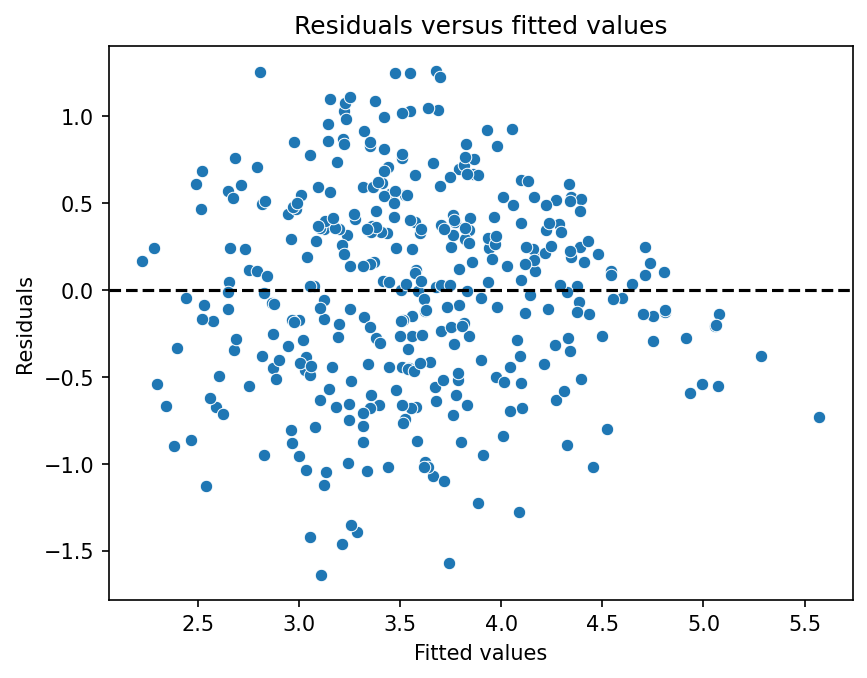

In [13]:
## Residual-fitted value plot
sns.scatterplot(
  x=model.fittedvalues,
  y=model.resid
)

plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals versus fitted values")
plt.show()

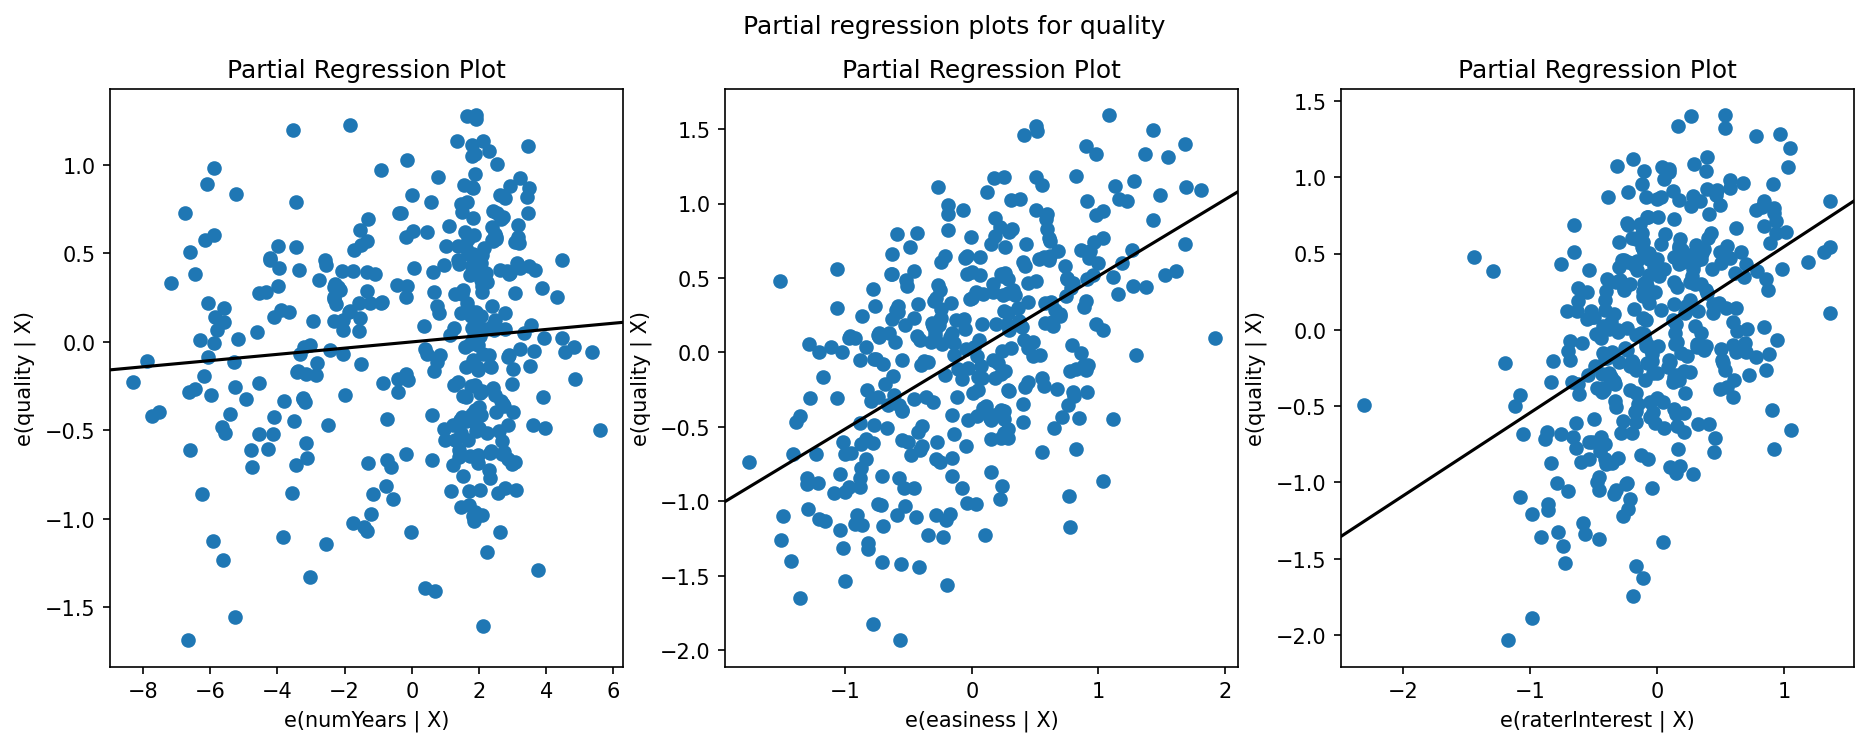

In [14]:
## Partial regression plots
# Regressing Y-residuals on X-residuals for Y = quality and X in (numYears, easiness, raterInterest), 
# conditioned on all other variables
continuousVars = ["numYears", "easiness", "raterInterest"]

subplotsPR: tuple[Figure, Axes] = plt.subplots(
  nrows=1, 
  ncols=3, 
  figsize=(15, 5)
)
figPR, axesPR = subplotsPR

for (idx, contVar) in enumerate(continuousVars):   # all three continuous variables in model
  # print(type(axesPR[idx]))

  sm.graphics.plot_partregress(
    endog="quality",    # Y-residual
    exog_i=contVar,     # X-residual
    exog_others=[       # Other variables controlled for
      "gender",
      "discipline",
      "pepper"
    ] + [v for v in continuousVars if v != contVar],
    data=rateProf,
    obs_labels=False,
    result_object=False,
    ax=axesPR[idx]
  )
  
figPR.suptitle("Partial regression plots for quality")
plt.show()

These plots are reflective of the model's estimated effects for their respective covariates, showing a modest to moderate positive contribution of each covariate to quality. Note that raterInterest may or may not include an outlier/influential point impacting the slope of its plot (the leftmost point around e(quality | X) = -0.5); we could examine this further later on with Cook's Distance plots.

2. **Residual-covariate plots** (check $E[\epsilon_i] = 0$)

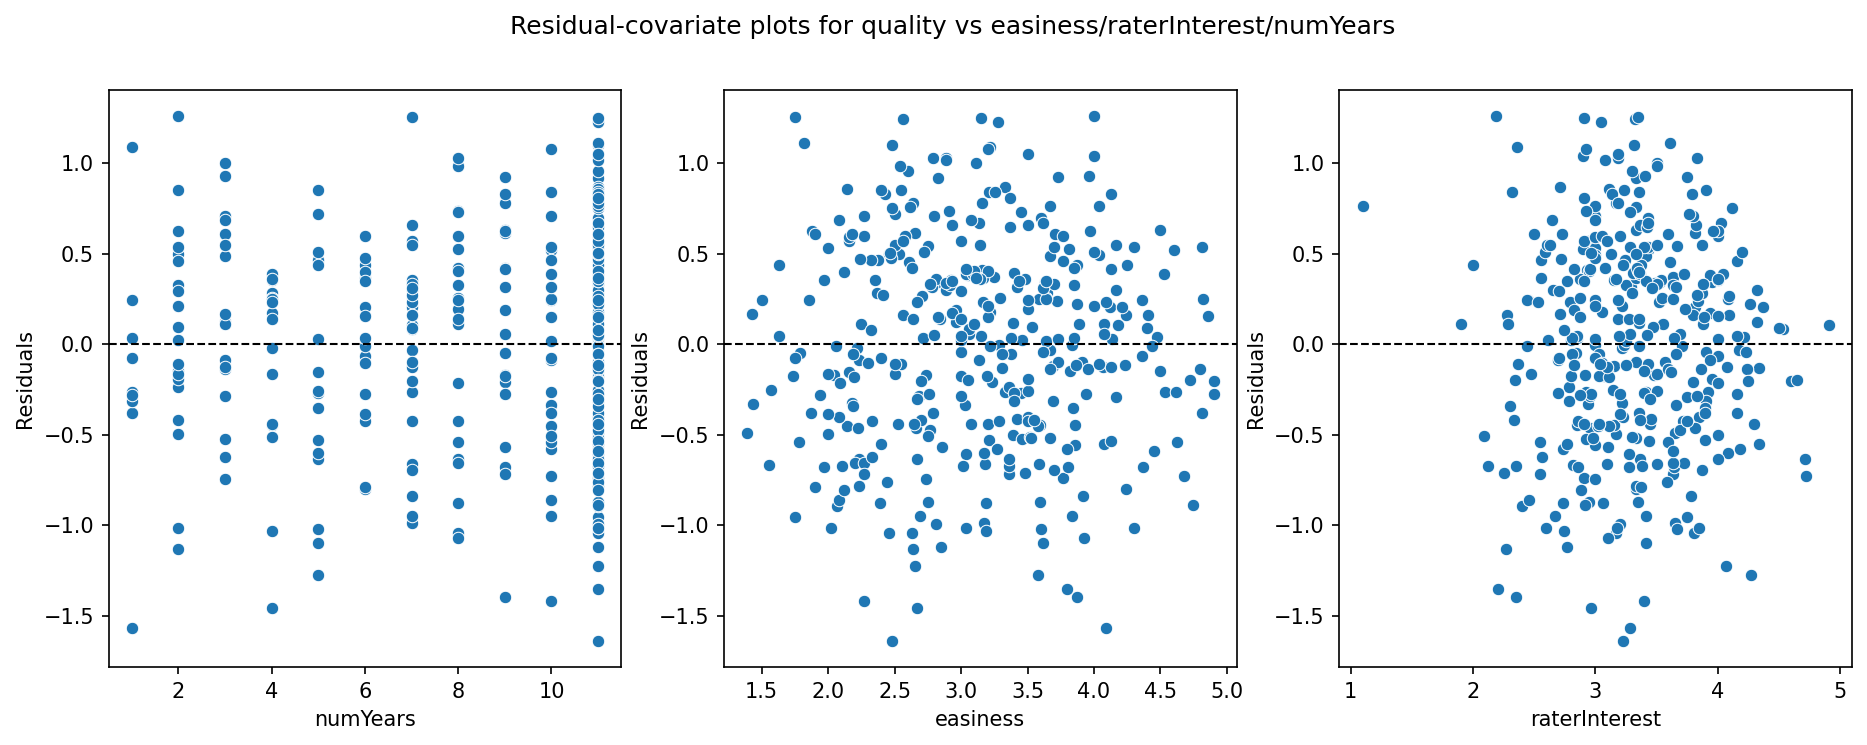

In [ ]:

subplotsRC: tuple[Figure, Axes] = plt.subplots(
  nrows=1, 
  ncols=3, 
  figsize=(15, 5)
)
figRC, axesRC = subplotsRC

# Extract internally studentized residuals from model
modelRows = model.model.data.row_labels
diagData = rateProf.loc[modelRows].copy()
diagData["studentized_residual"] = model.resid.to_numpy()


for (idx, contVar) in enumerate(continuousVars):
    # Plot residuals against original covariate
    sns.scatterplot(
        data=diagData,
        x=contVar,
        y="studentized_residual",
        ax=axesRC[idx]
    )

    # Reference line at y=0
    axesRC[idx].axhline(
        y=0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    # axesRC[idx].set_title(f"Residuals vs {contVar}")
    axesRC[idx].set_ylabel("Residuals")

figRC.suptitle("Residual-covariate plots for quality vs easiness/raterInterest/numYears")
plt.show()

3. **Q-Q plots (check assumption for normality of error terms)**

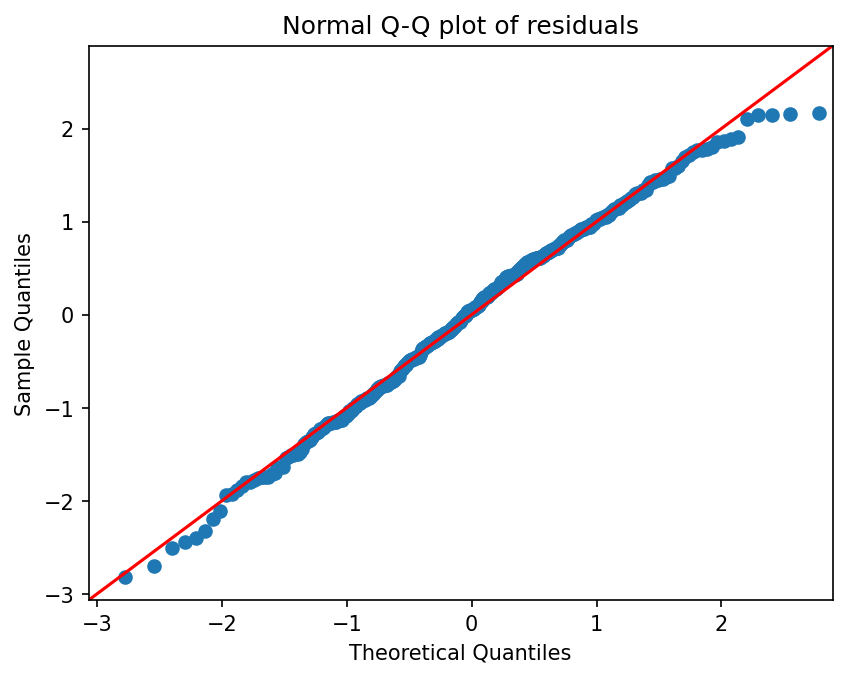

In [37]:
sm.qqplot(
    model.resid,
    line="45",
    fit=True
)

plt.title("Normal Q-Q plot of residuals")
plt.show()

We observe most of the points falling nearly perfectly onto the 45-degree line, save for a bit of deviation on the upper-right tail (this could be due to a few outliers). Overall, this points to the residuals/error terms likely being normally distributed, validating this assumption.

4. **Independence of error terms** ($Cov(\epsilon_i, \epsilon_j) = 0$)

Check dataset by hand for repeated rows, possible grouping of instructors mostly in certain departments/disciplines, other possible relations between instructors within certain groups. Overall, not something I can decisively conclude.